# Robot Health Monitoring & Fault Diagnostics System

## Project Overview

This project simulates a robot health monitoring system that tracks the operating conditions of three motors using sensor parameters such as rotational speed (RPM), operating temperature, and electrical current.

The system introduces simulated motor faults, detects abnormal operating conditions using predefined thresholds, classifies faults, and generates diagnostic reports and visualizations.

**Objective:** To demonstrate basic robotic system monitoring, sensor data analysis, fault detection, and condition-based diagnostics using Python.

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.random.seed(42)
print("Robot Health Monitoring System")
print("Libraries initialized successfully!")

Robot Health Monitoring System
Libraries initialized successfully!


## 1. Sensor Data Simulation & Fault Injection

Three motors are simulated under normal operating conditions over 100 observation time steps.

The following parameters are monitored:

- **Rotational Speed (RPM):** Motor operating speed.
- **Temperature (°C):** Motor operating temperature.
- **Electrical Current (A):** Current drawn by each motor.

Sensor readings are generated using NumPy with predefined statistical distributions. After the 60th observation, three abnormal operating conditions are introduced:

- Motor 1: Overheating.
- Motor 2: Excessive current consumption.
- Motor 3: Rotational speed degradation.

In [35]:
import numpy as np
import pandas as pd

# Baseline simulation duration
time_steps = 100

# Vector of generated time steps
time = np.arange(time_steps)

# Simulated standard baseline measurements across three motors
data = {
    "Time": time,

    "Motor_1_RPM": np.random.normal(1500, 30, time_steps),
    "Motor_2_RPM": np.random.normal(1450, 30, time_steps),
    "Motor_3_RPM": np.random.normal(1550, 30, time_steps),

    "Motor_1_Temp": np.random.normal(45, 2, time_steps),
    "Motor_2_Temp": np.random.normal(48, 2, time_steps),
    "Motor_3_Temp": np.random.normal(43, 2, time_steps),

    "Motor_1_Current": np.random.normal(3.0, 0.2, time_steps),
    "Motor_2_Current": np.random.normal(3.2, 0.2, time_steps),
    "Motor_3_Current": np.random.normal(2.8, 0.2, time_steps)
}

# Telemetry conversion into a structured pandas DataFrame
df = pd.DataFrame(data)

# Preview of initial data observations
df.head()

,Time,Motor_1_RPM,Motor_2_RPM,Motor_3_RPM,Motor_1_Temp,Motor_2_Temp,Motor_3_Temp,Motor_1_Current,Motor_2_Current,Motor_3_Current
0,0,1514.901425,1407.538878,1560.733621,43.342010,44.811145,44.852355,3.151398,3.095455,2.987657
1,1,1495.852071,1437.380640,1566.823536,43.879638,46.801250,46.818833,2.815567,3.409802,2.696791
2,2,1519.430656,1439.718565,1582.491537,46.494587,48.010487,40.202865,3.173921,3.059131,2.819224
3,3,1545.690896,1425.931682,1581.614062,46.220741,48.093961,44.125938,3.271128,2.918308,2.707545
4,4,1492.975399,1445.161429,1508.669919,44.958197,47.099869,41.698715,3.082687,2.888674,2.713101


## 2. Threshold-Based Fault Detection & Classification

The simulated sensor readings are evaluated against predefined operating limits.

| Parameter | Fault Condition | Threshold |
|---|---|---|
| Temperature | Overheating | > 70°C |
| Electrical Current | Overcurrent | > 5 A |
| Rotational Speed | Low Speed | < 1200 RPM |

Using conditional classification with NumPy, each motor is assigned a status of NORMAL, OVERHEATING, OVERCURRENT, or LOW SPEED.

The system subsequently generates diagnostic reports to identify abnormal operating conditions.

In [36]:
# Simulated faults injected starting from index 60

# Simulating Motor 1 overheating
df.loc[60:, "Motor_1_Temp"] += 30

# Simulating Motor 2 excessive current draw
df.loc[60:, "Motor_2_Current"] += 3

# Simulating Motor 3 rotational speed degradation
df.loc[60:, "Motor_3_RPM"] -= 400

# Visualizing sensor values around the injection index
df.iloc[58:65]

,Time,Motor_1_RPM,Motor_2_RPM,Motor_3_RPM,Motor_1_Temp,Motor_2_Temp,Motor_3_Temp,Motor_1_Current,Motor_2_Current,Motor_3_Current
58,58,1509.937903,1414.260895,1563.314583,45.645437,46.892701,43.788904,3.039617,3.028328,2.689555
59,59,1529.266354,1469.696608,1573.239022,43.345538,45.604244,42.158031,2.971128,3.340062,2.926586
60,60,1485.624773,1420.759550,1122.192086,76.038693,51.929450,43.579550,2.885268,6.084872,2.840585
61,61,1494.430231,1473.612538,1148.214239,78.065478,48.070527,47.150802,2.890628,6.224402,2.496851
62,62,1466.809951,1484.757867,1052.761980,74.782480,46.600549,44.742249,2.993449,6.712017,3.109501
63,63,1464.113801,1425.379530,1119.268371,75.803423,48.427960,42.347953,2.891315,6.180788,3.159176
64,64,1524.375775,1478.901284,1142.422955,76.380288,47.775344,45.402428,2.857431,6.429855,2.677442


In [37]:
# Operational limits used for classification thresholds
TEMP_LIMIT = 70
CURRENT_LIMIT = 5
RPM_MIN = 1200

# Dynamic loop to classify fault occurrences across all available motor systems in the dataframe
motor_ids = sorted(list(set(col.split('_')[1] for col in df.columns if col.startswith('Motor_') and col.endswith('_RPM'))))

for m_id in motor_ids:
    df[f"Motor_{m_id}_Fault"] = np.select(
        [
            df[f"Motor_{m_id}_Temp"] > TEMP_LIMIT,
            df[f"Motor_{m_id}_Current"] > CURRENT_LIMIT,
            df[f"Motor_{m_id}_RPM"] < RPM_MIN
        ],
        [
            "OVERHEATING",
            "OVERCURRENT",
            "LOW SPEED"
        ],
        default="NORMAL"
    )

# Displaying diagnostic outputs for all motors across the diagnostic window
fault_cols = [f"Motor_{m_id}_Fault" for m_id in motor_ids]
df[["Time"] + fault_cols].iloc[58:65]

,Time,Motor_1_Fault,Motor_2_Fault,Motor_3_Fault
58,58,NORMAL,NORMAL,NORMAL
59,59,NORMAL,NORMAL,NORMAL
60,60,OVERHEATING,OVERCURRENT,LOW SPEED
61,61,OVERHEATING,OVERCURRENT,LOW SPEED
62,62,OVERHEATING,OVERCURRENT,LOW SPEED
63,63,OVERHEATING,OVERCURRENT,LOW SPEED
64,64,OVERHEATING,OVERCURRENT,LOW SPEED


In [38]:

print("ROBOT HEALTH DIAGNOSTIC REPORT")
print("--------------------------------")

print("Motor 1 overheating events:",
      (df["Motor_1_Fault"] == "OVERHEATING").sum())

print("Motor 2 overcurrent events:",
      (df["Motor_2_Fault"] == "OVERCURRENT").sum())

print("Motor 3 low-speed events:",
      (df["Motor_3_Fault"] == "LOW SPEED").sum())


ROBOT HEALTH DIAGNOSTIC REPORT
--------------------------------
Motor 1 overheating events: 40
Motor 2 overcurrent events: 40
Motor 3 low-speed events: 39


## 3. Motor Performance Visualization & Health Monitoring

Sensor readings are plotted against their respective operating thresholds to visualize changes in motor behaviour.

The overall robot health status is determined by combining the diagnostic results of all three motors.

- **HEALTHY:** All three motors operate within their defined limits.
- **WARNING:** At least one motor exhibits an abnormal operating condition.

A fault event log is also generated to record the observation time, affected motor, and detected fault.

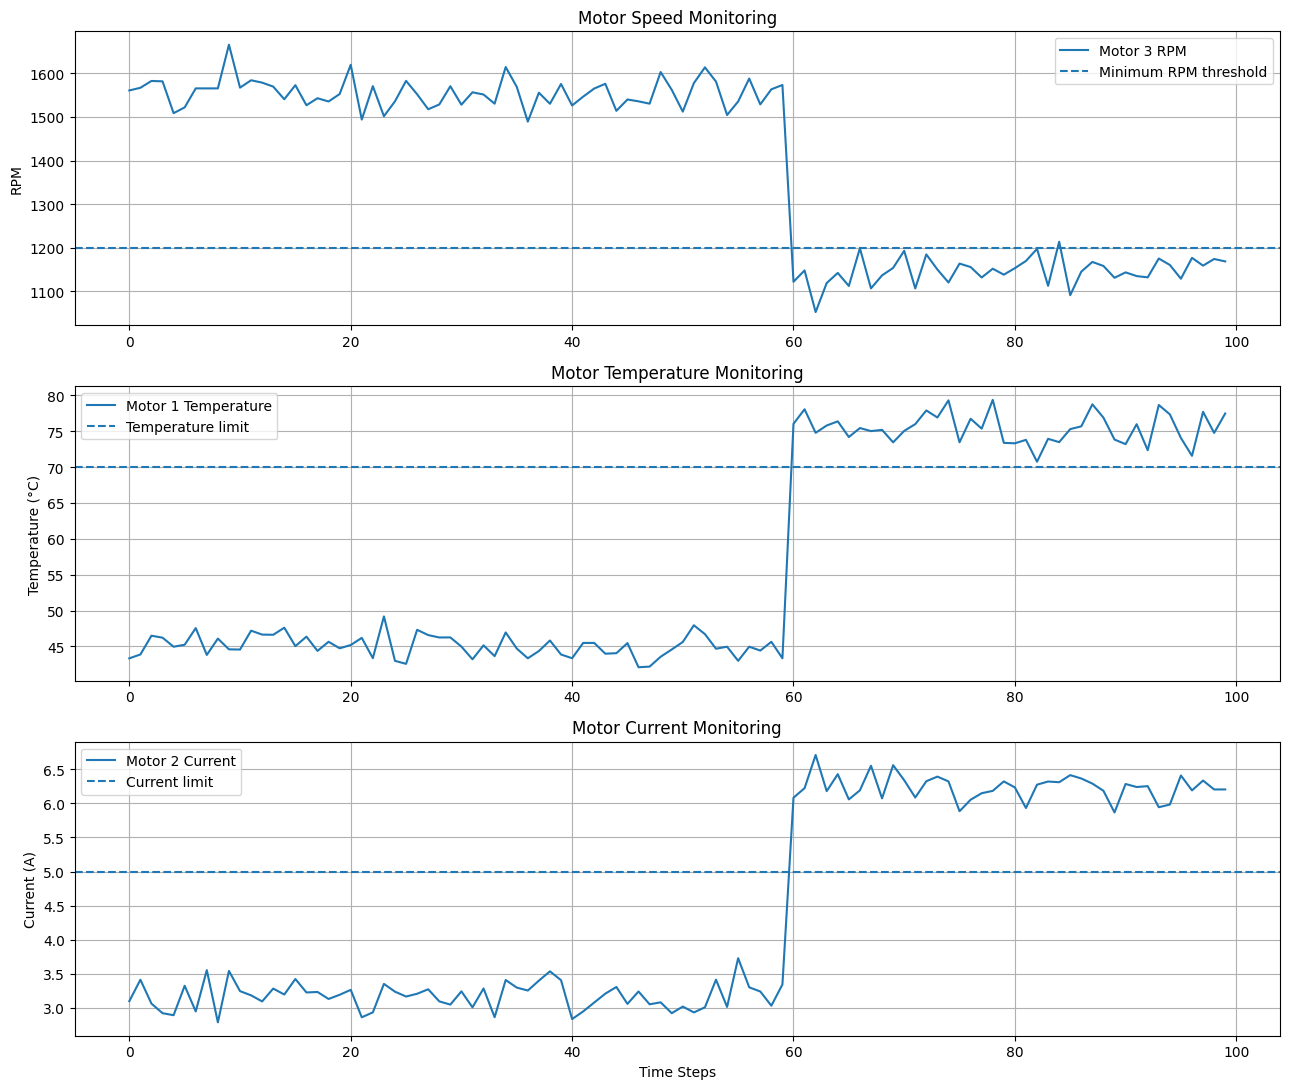

In [39]:

fig, axes = plt.subplots(3, 1, figsize=(13, 11))

# Motor RPM
axes[0].plot(df["Time"], df["Motor_3_RPM"], label="Motor 3 RPM")
axes[0].axhline(1200, linestyle="--", label="Minimum RPM threshold")
axes[0].set_title("Motor Speed Monitoring")
axes[0].set_ylabel("RPM")
axes[0].legend()
axes[0].grid(True)

# Motor Temperature
axes[1].plot(df["Time"], df["Motor_1_Temp"], label="Motor 1 Temperature")
axes[1].axhline(70, linestyle="--", label="Temperature limit")
axes[1].set_title("Motor Temperature Monitoring")
axes[1].set_ylabel("Temperature (°C)")
axes[1].legend()
axes[1].grid(True)

# Motor Current
axes[2].plot(df["Time"], df["Motor_2_Current"], label="Motor 2 Current")
axes[2].axhline(5, linestyle="--", label="Current limit")
axes[2].set_title("Motor Current Monitoring")
axes[2].set_xlabel("Time Steps")
axes[2].set_ylabel("Current (A)")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()


In [40]:
# Assessment of overall system health status based on combined faults

df["Robot_Status"] = np.where(
    (df["Motor_1_Fault"] != "NORMAL") |
    (df["Motor_2_Fault"] != "NORMAL") |
    (df["Motor_3_Fault"] != "NORMAL"),
    "WARNING",
    "HEALTHY"
)

# Instantiation of the historical fault logs

events = []

for i, row in df.iterrows():

    if row["Motor_1_Fault"] != "NORMAL":
        events.append([row["Time"], "Motor 1",
                       row["Motor_1_Fault"]])

    if row["Motor_2_Fault"] != "NORMAL":
        events.append([row["Time"], "Motor 2",
                       row["Motor_2_Fault"]])

    if row["Motor_3_Fault"] != "NORMAL":
        events.append([row["Time"], "Motor 3",
                       row["Motor_3_Fault"]])

event_log = pd.DataFrame(
    events,
    columns=["Time", "Component", "Fault"]
)

print("ROBOT HEALTH STATUS")
print("-------------------")
print(df["Robot_Status"].value_counts())

print("\nFAULT EVENT LOG")
display(event_log.head(10))

ROBOT HEALTH STATUS
-------------------
Robot_Status
HEALTHY    60
WARNING    40
Name: count, dtype: int64

FAULT EVENT LOG


,Time,Component,Fault
0,60,Motor 1,OVERHEATING
1,60,Motor 2,OVERCURRENT
2,60,Motor 3,LOW SPEED
3,61,Motor 1,OVERHEATING
4,61,Motor 2,OVERCURRENT
5,61,Motor 3,LOW SPEED
6,62,Motor 1,OVERHEATING
7,62,Motor 2,OVERCURRENT
8,62,Motor 3,LOW SPEED
9,63,Motor 1,OVERHEATING


In [41]:
!pip install plotly -q

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px

In [42]:
# Extraction of cumulative metrics for visualization status summaries
healthy = (df["Robot_Status"] == "HEALTHY").sum()
warning = (df["Robot_Status"] == "WARNING").sum()

print("===================================")
print("       ROBOT MONITORING SYSTEM")
print("===================================")

print(f"Total observations : {len(df)}")
print(f"Healthy            : {healthy}")
print(f"Warning            : {warning}")

# Multi-subplot interactive sensor monitoring dashboard configuration
fig = make_subplots(
    rows=3, cols=1,
    subplot_titles=(
        "Motor 3 - RPM",
        "Motor 1 - Temperature",
        "Motor 2 - Current"
    ),
    vertical_spacing=0.12
)

# Speed timeseries mapping with baseline annotation
fig.add_trace(
    go.Scatter(
        x=df["Time"], y=df["Motor_3_RPM"],
        name="RPM"
    ), row=1, col=1
)

fig.add_hline(
    y=1200, line_dash="dash",
    annotation_text="Minimum RPM",
    row=1, col=1
)

# Thermal timeseries mapping with maximum threshold annotation
fig.add_trace(
    go.Scatter(
        x=df["Time"], y=df["Motor_1_Temp"],
        name="Temperature"
    ), row=2, col=1
)

fig.add_hline(
    y=70, line_dash="dash",
    annotation_text="Temperature limit",
    row=2, col=1
)

# Electric current timeseries mapping with current limit annotation
fig.add_trace(
    go.Scatter(
        x=df["Time"], y=df["Motor_2_Current"],
        name="Current"
    ), row=3, col=1
)

fig.add_hline(
    y=5, line_dash="dash",
    annotation_text="Current limit",
    row=3, col=1
)

fig.update_layout(
    title="Robot Health Monitoring Dashboard",
    height=850,
    template="plotly_white",
    showlegend=False
)

fig.show()

       ROBOT MONITORING SYSTEM
Total observations : 100
Healthy            : 60


## 4. Interactive Diagnostic Dashboard

An interactive monitoring dashboard is developed using Plotly and ipywidgets to provide a consolidated view of robot operating conditions.

### Dashboard Features

- Interactive monitoring of motor RPM, temperature, and electrical current.
- Visual representation of sensor readings against predefined thresholds.
- Fault distribution chart showing the frequency of detected fault types.
- Event summary displaying total faults, healthy observations, and warning observations.
- Motor-wise fault summary and event logging.
- Interactive motor selection for inspecting individual sensor readings and diagnostic status.

The dashboard provides a simple interface for monitoring motor performance and identifying potential equipment faults.

In [43]:
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# 1. FAULT DISTRIBUTION CHART

fault_counts = event_log["Fault"].value_counts().reset_index()
fault_counts.columns = ["Fault Type", "Number of Events"]

fig_fault = px.bar(
    fault_counts,
    x="Fault Type",
    y="Number of Events",
    color="Fault Type",
    title="Fault Distribution Across Robot Motors",
    text="Number of Events",
    template="plotly_white"
)

fig_fault.update_layout(
    showlegend=False,
    height=400
)

fig_fault.show()


# 2. EVENT SUMMARY STATS

total_events = len(event_log)
affected_observations = df["Robot_Status"].eq("WARNING").sum()
healthy_observations = df["Robot_Status"].eq("HEALTHY").sum()

print("========== EVENT SUMMARY ==========")
print(f"Total fault events: {total_events}")
print(f"Observations with faults: {affected_observations}")
print(f"Healthy observations: {healthy_observations}")
print(f"Fault-free percentage: {healthy_observations / len(df) * 100:.1f}%")

print("\nMOTOR-WISE FAULT SUMMARY")

motor_summary = event_log.groupby(
    ["Component", "Fault"]
).size().reset_index(name="Fault Events")

display(motor_summary)


# 3. INTERACTIVE MOTOR SELECTION WIDGETS

motor_selector = widgets.Dropdown(
    options=["Motor_1", "Motor_2", "Motor_3"],
    value="Motor_1",
    description="Select Motor:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="300px")
)

motor_output = widgets.Output()


# 4. MOTOR INSPECTION CALLBACK

def inspect_motor(change=None):
    with motor_output:
        clear_output(wait=True)

        motor = motor_selector.value
        rpm_col = f"{motor}_RPM"
        temp_col = f"{motor}_Temp"
        current_col = f"{motor}_Current"
        fault_col = f"{motor}_Fault"

        fault_count = (df[fault_col] != "NORMAL").sum()

        print("MOTOR INSPECTION REPORT")
        print("------------------------")
        print(f"Selected motor: {motor}")
        print(f"Detected faults: {fault_count}")

        if fault_count > 0:
            print("Motor condition: WARNING")
        else:
            print("Motor condition: NORMAL")

        # Three-panel sensor graph layout
        fig = make_subplots(
            rows=3,
            cols=1,
            subplot_titles=[
                "Rotational Speed",
                "Operating Temperature",
                "Electrical Current"
            ],
            vertical_spacing=0.12
        )

        # RPM timeseries
        fig.add_trace(
            go.Scatter(x=df["Time"], y=df[rpm_col], name="RPM"),
            row=1, col=1
        )
        fig.add_hline(
            y=1200, line_dash="dash", annotation_text="Minimum RPM",
            row=1, col=1
        )

        # Temperature timeseries
        fig.add_trace(
            go.Scatter(x=df["Time"], y=df[temp_col], name="Temperature"),
            row=2, col=1
        )
        fig.add_hline(
            y=70, line_dash="dash", annotation_text="Temperature limit",
            row=2, col=1
        )

        # Current timeseries
        fig.add_trace(
            go.Scatter(x=df["Time"], y=df[current_col], name="Current"),
            row=3, col=1
        )
        fig.add_hline(
            y=5, line_dash="dash", annotation_text="Current limit",
            row=3, col=1
        )

        fig.update_layout(
            title=f"{motor} - Sensor Monitoring",
            height=800,
            template="plotly_white",
            showlegend=False
        )

        fig.update_xaxes(title_text="Time Steps", row=3, col=1)
        fig.update_yaxes(title_text="RPM", row=1, col=1)
        fig.update_yaxes(title_text="Temperature (°C)", row=2, col=1)
        fig.update_yaxes(title_text="Current (A)", row=3, col=1)

        fig.show()

        print("\nLATEST SENSOR READINGS")
        display(df[["Time", rpm_col, temp_col, current_col, fault_col]].tail(5).round(2))


# Dynamic dashboard updates on motor selection changes
motor_selector.observe(inspect_motor, names="value")
display(motor_selector, motor_output)

# Initial presentation setup
inspect_motor()

========== EVENT SUMMARY ==========
Total fault events: 119
Observations with faults: 40
Healthy observations: 60
Fault-free percentage: 60.0%

MOTOR-WISE FAULT SUMMARY


,Component,Fault,Fault Events
0,Motor 1,OVERHEATING,40
1,Motor 2,OVERCURRENT,40
2,Motor 3,LOW SPEED,39


Dropdown(description='Select Motor:', layout=Layout(width='300px'), options=('Motor_1', 'Motor_2', 'Motor_3'),…

Output()